# Overfitting, Bias, and Variance

**Objective:** Study how model complexity affects prediction error, variance, and generalization.

**Dataset used:** `data/auto-mpg.data`

**Main techniques used:** Linear regression, feature subset comparison, mean squared error, variance analysis, cross-validation


## Why Overfitting Matters

This notebook explores overfitting, bias, and variance through a fuel consumption prediction example.


In [1]:
import pandas as pd
pd.options.mode.chained_assignment = None  # default='warn'
import numpy as np
colomuns =['mpg','cylinders','displacement','horsepower','weight','acceleration','model year','origin','car name']
cars = pd.read_csv('data/auto-mpg.data', delim_whitespace=True, names=colomuns)
filtred_cars = cars[cars['horsepower'] != '?']
filtred_cars['horsepower'] = filtred_cars['horsepower'].astype(float)
filtred_cars.head()


C:\Users\user\AppData\Local\Temp\ipykernel_11864\3352201453.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  cars = pd.read_csv('auto-mpg.data', delim_whitespace=True, names=colomuns)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## Bias and Variance

Bias comes from overly simple assumptions, while variance reflects sensitivity to fluctuations in the training data.


In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np
def train_and_test(cols):
    #separer en carctéristiques et cible*
    features = filtred_cars[cols]
    target = filtred_cars['mpg']
    #adapter notre modele
    Lr = LinearRegression()
    Lr.fit(features, target)
    #faire des prédictions sur le set de training
    predictions = Lr.predict(features)
    #calculer l'erreur de notre modèle
    mse = mean_squared_error(target, predictions)
    print("mean squared error:", mse)
    var = np.var(predictions)
    return (mse, var)
cyl_mse, cyl_var = train_and_test(['cylinders'])
weight_mse, weight_var = train_and_test(['weight'])
print("cylinders mse:", cyl_mse, "variance:", cyl_var)
print("weight mse:", weight_mse, "variance:", weight_var)


mean squared error: 24.02017956815553
mean squared error: 18.6766165974193
cylinders mse: 24.02017956815553 variance: 36.742558874160174
weight mse: 18.6766165974193 variance: 42.08612184489639


Modeles multivariés

Utiliser la fonction train_and_test pour entrainer des modèles de régression linéaires en utilisant les colonnes suivantes en
caractéristiques:

. colonnes: cylinders, displacement.
. MSE: two_mse, variance: two_var.
. colonnes: cylinders, displacement, horsepower.
. MSE: three_mse, variance: three_var.
· colonnes: cylinders, displacement, horsepower, weight.
. MSE: four_mse, variance: four_var.
. colonnes: cylinders, displacement, horsepower, weight, acceleration.
. MSE: five_mse, variance: five_var.
. colonnes: cylinders, displacement, horsepower, weight, acceleration, model year
. MSE: six_mse, variance: six_var.
. colonnes: cylinders, displacement, horsepower, weight, acceleration, model year, origin
. MSE: seven_mse, variance: seven_var.

Afficher chaque valeur


In [4]:
one_mse, one_var = train_and_test(['cylinders'])
two_mse, two_var = train_and_test(['cylinders', 'displacement']) 
three_mse, three_var = train_and_test(['cylinders', 'displacement','horsepower'])
four_mse, four_var = train_and_test(['cylinders', 'displacement','horsepower','weight'])
five_mse, five_var = train_and_test(['cylinders', 'displacement','horsepower','weight','acceleration'])
six_mse, six_var = train_and_test(['cylinders', 'displacement','horsepower','weight','acceleration','model year'])
seven_mse, seven_var = train_and_test(['cylinders', 'displacement','horsepower','weight','acceleration','model year','origin'])
print("one mse:", one_mse, "variance:", one_var)
print("two mse:", two_mse, "variance:", two_var)
print("three mse:", three_mse, "variance:", three_var)
print("four mse:", four_mse, "variance:", four_var)
print("five mse:", five_mse, "variance:", five_var)
print("six mse:", six_mse, "variance:", six_var)
print("seven mse:", seven_mse, "variance:", seven_var)


mean squared error: 24.02017956815553
mean squared error: 21.282057055586364
mean squared error: 20.25295483971423
mean squared error: 17.763860571843846
mean squared error: 17.761396105406217
mean squared error: 11.590170981415229
mean squared error: 10.847480945000452
one mse: 24.02017956815553 variance: 36.742558874160174
two mse: 21.282057055586364 variance: 39.480681386729394
three mse: 20.25295483971423 variance: 40.50978360260138
four mse: 17.763860571843846 variance: 42.99887787047188
five mse: 17.761396105406217 variance: 43.00134233690938
six mse: 11.590170981415229 variance: 49.17256746090048
seven mse: 10.847480945000452 variance: 49.91525749731507


## Cross-Validation

As model complexity grows, bias can decrease while variance increases. Cross-validation provides a more reliable view of that trade-off.


In [5]:
from sklearn.model_selection import KFold

def train_and_cross_val(cols):
    features = filtred_cars[cols]
    target = filtred_cars['mpg']
    variances_values = []
    mse_values = []
    #instance KFOLD
    kf = KFold(n_splits=10 , shuffle=True, random_state=3)
    #iterer sur les splits
    for train_index, test_index in kf.split(filtred_cars):
        #séparer en training et test
        X_train, X_test = features.iloc[train_index], features.iloc[test_index]
        y_train, y_test = target.iloc[train_index], target.iloc[test_index]
        #adapter notre modele
        Lr = LinearRegression()
        Lr.fit(X_train, y_train)
        #faire des prédictions sur le set de test
        predictions = Lr.predict(X_test)
        #calculer l'erreur de notre modèle
        mse = mean_squared_error(y_test, predictions)
        mse_values.append(mse)
        var = np.var(predictions)
        variances_values.append(var)
    return (np.mean(mse_values), np.mean(variances_values))



two_mse, two_var = train_and_cross_val(['cylinders', 'displacement']) 
three_mse, three_var = train_and_cross_val(['cylinders', 'displacement','horsepower'])
four_mse, four_var = train_and_cross_val(['cylinders', 'displacement','horsepower','weight'])
five_mse, five_var = train_and_cross_val(['cylinders', 'displacement','horsepower','weight','acceleration'])
six_mse, six_var = train_and_cross_val(['cylinders', 'displacement','horsepower','weight','acceleration','model year'])
seven_mse, seven_var = train_and_cross_val(['cylinders', 'displacement','horsepower','weight','acceleration','model year','origin'])
print("two mse:", two_mse, "variance:", two_var)
print("three mse:", three_mse, "variance:", three_var)
print("four mse:", four_mse, "variance:", four_var)
print("five mse:", five_mse, "variance:", five_var)
print("six mse:", six_mse, "variance:", six_var)
print("seven mse:", seven_mse, "variance:", seven_var)


two mse: 21.584370274954374 variance: 38.90252531375603
three mse: 20.655622193882955 variance: 40.09128795660695
four mse: 18.169683239081888 variance: 42.507643643644364
five mse: 18.283038517172052 variance: 42.598736300146825
six mse: 12.099685425467122 variance: 48.92824696771808
seven mse: 11.418131971812064 variance: 49.90431373098732


## Visualize the Bias-Variance Trade-off

The final plot compares cross-validation mean squared error and variance as the number of input features increases.


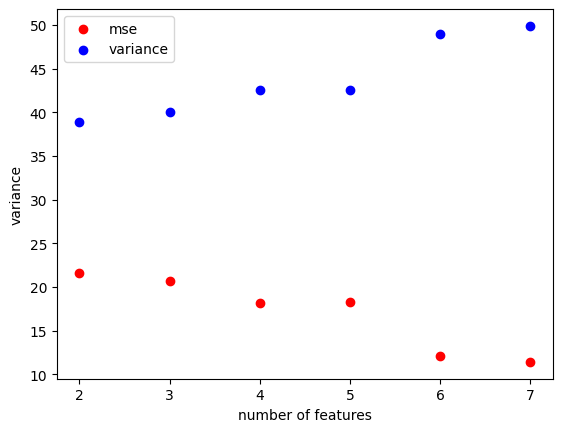

In [6]:

two_mse, two_var = train_and_cross_val(['cylinders', 'displacement']) 
three_mse, three_var = train_and_cross_val(['cylinders', 'displacement','horsepower'])
four_mse, four_var = train_and_cross_val(['cylinders', 'displacement','horsepower','weight'])
five_mse, five_var = train_and_cross_val(['cylinders', 'displacement','horsepower','weight','acceleration'])
six_mse, six_var = train_and_cross_val(['cylinders', 'displacement','horsepower','weight','acceleration','model year'])
seven_mse, seven_var = train_and_cross_val(['cylinders', 'displacement','horsepower','weight','acceleration','model year','origin'])
import matplotlib.pyplot as plt
plt.scatter([2,3,4,5,6,7], [two_mse, three_mse, four_mse, five_mse, six_mse, seven_mse], color='red')
plt.xlabel('number of features')
plt.ylabel('mean squared error')
plt.scatter([2,3,4,5,6,7], [two_var, three_var, four_var, five_var, six_var, seven_var], color='blue')
plt.xlabel('number of features')
plt.ylabel('variance')
plt.legend(['mse', 'variance'])
plt.show()


## Conclusion

**What was done:** Compared models of different complexity and measured how error and variance change with more features.

**What was learned:** Improving training fit does not always improve generalization, which makes validation essential.

**Possible improvements:** Add regularization techniques and compare results with nonlinear models.
